# In-class Competition Tutorial


In [56]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries


In [57]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive


In [58]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [59]:
# Specify the directory where this notebook is located after %cd.
%cd "/content/drive/MyDrive/Competition"

/content/drive/MyDrive/Competition


In [60]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2.Loading the Data

### 2.1 Data Overview


In [61]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

In [62]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [63]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


FEATURE SELECTION


In [64]:
use_features = [
    #Baseline features
     "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "DAYS_BIRTH", "DAYS_EMPLOYED",
    "ORGANIZATION_TYPE", "OWN_CAR_AGE",
    "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
    "CODE_GENDER", "REGION_RATING_CLIENT",
    "DAYS_LAST_PHONE_CHANGE", "CNT_FAM_MEMBERS",
    "CNT_CHILDREN", "NAME_INCOME_TYPE",
    "NAME_HOUSING_TYPE", "REGION_POPULATION_RELATIVE",
    "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",

    #Demographic and socioeconomic features
    "NAME_FAMILY_STATUS",
    "OCCUPATION_TYPE",
    "FLAG_EMP_PHONE",
    "FLAG_WORK_PHONE",
    "FLAG_MOBIL",

    #Basic financial ratios
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_GOODS_RATIO",
    "GOODS_INCOME_RATIO",
    "ANNUITY_CREDIT_RATIO",
    "INCOME_PER_PERSON",
    "CREDIT_PER_PERSON",
    "CREDIT_MINUS_GOODS",
    "AGE_YEARS",
    "INCOME_TO_AGE_RATIO",

    #Employment and external-score engineering
     "EMPLOYED_TO_AGE_RATIO",
    "EXT_SOURCES_MEAN",
    "EXT_SOURCES_PROD",
    "EXT_SOURCES_STD",

    #Additional affordability features

    "INCOME_AFTER_ANNUITY",
    "ESTIMATED_REPAYMENT_DURATION",
    "CREDIT_TO_FAMILY_INCOME_CAPACITY",
    "GOODS_FINANCING_GAP_RATIO"

]

In [65]:
for df in [train, test]:
    # 1. Employment length relative to age (Fraction of life spent working)
    df['EMPLOYED_TO_AGE_RATIO'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']

    # 2. Combined External Scores (EXT_SOURCE columns are massive predictors in Home Credit)
    df['EXT_SOURCES_MEAN'] = df[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
    df['EXT_SOURCES_PROD'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
    df['EXT_SOURCES_STD'] = df[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].std(axis=1)

    # 3. Debt burden score
    df['DEBT_BURDEN_SCORE'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1)

    # 4. Goods-to-Income: How expensive are the goods relative to annual income?
    df['GOODS_INCOME_RATIO'] = df['AMT_GOODS_PRICE'] / (df['AMT_INCOME_TOTAL'] + 1)

    # 5. Annuity-to-Credit: Repayment burden relative to total loan amount
    df['ANNUITY_CREDIT_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1)

    # 6. Income-per-Person / Family Burden: Income divided by family members
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS'].replace(0, 1)

    # 7. Credit-per-Person: Credit size per family member
    df['CREDIT_PER_PERSON'] = df['AMT_CREDIT'] / df['CNT_FAM_MEMBERS'].replace(0, 1)

    # 8. Credit Minus Goods: Measures debt overhang/extra cash requested on top of goods
    df['CREDIT_MINUS_GOODS'] = df['AMT_CREDIT'] - df['AMT_GOODS_PRICE']

    # 9. Age in Years (from negative days)
    df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365.25

    # 10. Income-to-Age Ratio: Earning capacity relative to age
    df['INCOME_TO_AGE_RATIO'] = df['AMT_INCOME_TOTAL'] / df['AGE_YEARS']

    # 11. Credit-to-Income Ratio (How large is the loan relative to earnings?)
    df['CREDIT_INCOME_RATIO'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']

    # 12. Annuity-to-Income Ratio (How heavy is the monthly repayment burden?)
    df['ANNUITY_INCOME_RATIO'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']

    # 13. Credit-to-Goods Price Ratio (Loan amount versus the actual item value)
    df['CREDIT_GOODS_RATIO'] = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']

    # 14. Income remaining after annualized repayments
    df['INCOME_AFTER_ANNUITY'] = df['AMT_INCOME_TOTAL'] - (12 * df['AMT_ANNUITY'])

    # 15. Estimated loan repayment duration
    df['ESTIMATED_REPAYMENT_DURATION'] = df['AMT_CREDIT'] / (df['AMT_ANNUITY'] + 1)

    # 16. Credit relative to family income capacity
    df['CREDIT_TO_FAMILY_INCOME_CAPACITY'] = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS'].replace(0, 1) + 1)

    # 17. Goods financing gap ratio
    df['GOODS_FINANCING_GAP_RATIO'] = (df['AMT_CREDIT'] - df['AMT_GOODS_PRICE']) / (df['AMT_GOODS_PRICE'] + 1)



In [66]:
target = train["TARGET"].values
train = train[use_features]
train["TARGET"] = target
test = test[use_features]

In [67]:
# List of columns to convert to integer
cols_to_convert = ["AMT_INCOME_TOTAL","OWN_CAR_AGE","AMT_CREDIT","AMT_GOODS_PRICE","DAYS_LAST_PHONE_CHANGE","CNT_FAM_MEMBERS","DAYS_REGISTRATION","INCOME_PER_PERSON","CREDIT_PER_PERSON","CREDIT_MINUS_GOODS","INCOME_AFTER_ANNUITY","AGE_YEARS"]

for col in cols_to_convert:
    if col in train.columns:
        # Fill any NaN values if present before converting (e.g., with 0 or a placeholder)
        train[col] = train[col].fillna(0).astype(int)

    if col in test.columns:
        test[col] = test[col].fillna(0).astype(int)



In [68]:
# Explicitly list the columns you want to convert to object data type
cols_to_convert_to_object = ["REGION_RATING_CLIENT", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE","FLAG_MOBIL","AMT_REQ_CREDIT_BUREAU_HOUR","AMT_REQ_CREDIT_BUREAU_QRT","AMT_REQ_CREDIT_BUREAU_YEAR","AMT_REQ_CREDIT_BUREAU_MON"]

for col in cols_to_convert_to_object:
    if col in train.columns:
        train[col] = train[col].astype(object)
    if col in test.columns:
        test[col] = test[col].astype(object)

In [69]:
# Separate columns by their data types
numeric_cols = train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()
object_cols = train.select_dtypes(include=["object", "category"]).columns.tolist()

# Ensure 'TARGET' stays at the very end if it's present in train
if "TARGET" in numeric_cols:
    numeric_cols.remove("TARGET")
    target_in_numeric = True
else:
    target_in_numeric = False

# Reorder: Numeric columns first, then object columns, and TARGET at the tail
new_column_order = numeric_cols + object_cols
if target_in_numeric or "TARGET" in train.columns:
    if "TARGET" not in new_column_order:
        new_column_order.append("TARGET")

# Apply the new ordering to both train and test datasets
train = train[new_column_order]

# For test set (which doesn't have the TARGET column)
test_cols = [col for col in new_column_order if col != "TARGET"]
test = test[test_cols]

# Verify the new structure
print(f"Total columns reordered: {len(train.columns)}")
train.info()

Total columns reordered: 50
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 50 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   AMT_INCOME_TOTAL                  171202 non-null  int64  
 1   EXT_SOURCE_1                      52274 non-null   float64
 2   EXT_SOURCE_2                      170833 non-null  float64
 3   EXT_SOURCE_3                      116616 non-null  float64
 4   DAYS_BIRTH                        171202 non-null  int64  
 5   DAYS_EMPLOYED                     171202 non-null  int64  
 6   OWN_CAR_AGE                       171202 non-null  int64  
 7   AMT_CREDIT                        171202 non-null  int64  
 8   AMT_ANNUITY                       171202 non-null  float64
 9   AMT_GOODS_PRICE                   171202 non-null  int64  
 10  DAYS_LAST_PHONE_CHANGE            171202 non-null  int64  
 11  CNT_FAM_MEMBERS         

In [70]:
# Print unique values for all object (categorical) columns
for col in train.select_dtypes(include=["object"]).columns:
    print(f"Column: {col}")
    print(train[col].unique())
    print("-" * 50)

Column: NAME_CONTRACT_TYPE
['Cash loans' 'Revolving loans']
--------------------------------------------------
Column: ORGANIZATION_TYPE
['School' 'XNA' 'Postal' 'Business Entity Type 3' 'Transport: type 4'
 'Trade: type 3' 'Military' 'Self-employed' 'Bank'
 'Business Entity Type 2' 'Kindergarten' 'Trade: type 7' 'Hotel'
 'Services' 'Other' 'Medicine' 'Government' 'Construction' 'Agriculture'
 'University' 'Religion' 'Industry: type 4' 'Advertising' 'Legal Services'
 'Business Entity Type 1' 'Industry: type 9' 'Industry: type 11'
 'Industry: type 3' 'Trade: type 6' 'Industry: type 10' 'Trade: type 1'
 'Housing' 'Industry: type 1' 'Security Ministries' 'Industry: type 12'
 'Security' 'Industry: type 7' 'Transport: type 3' 'Transport: type 2'
 'Police' 'Realtor' 'Restaurant' 'Culture' 'Insurance' 'Emergency'
 'Mobile' 'Electricity' 'Telecom' 'Trade: type 2' 'Industry: type 13'
 'Industry: type 2' 'Transport: type 1' 'Industry: type 5'
 'Industry: type 6' 'Cleaning' 'Trade: type 4' 'Indus

## 3.Visualizing and Understanding the Data

### 3.1 Checking missing values


In [71]:
# Check missing values of test data
test.isnull().sum()

,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_1,42912
EXT_SOURCE_2,130
EXT_SOURCE_3,19690
DAYS_BIRTH,0
DAYS_EMPLOYED,0
OWN_CAR_AGE,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0


### 3.2 Visualization and analysis of  features


#### ALL NUMERIC COLUMN GRAPHS

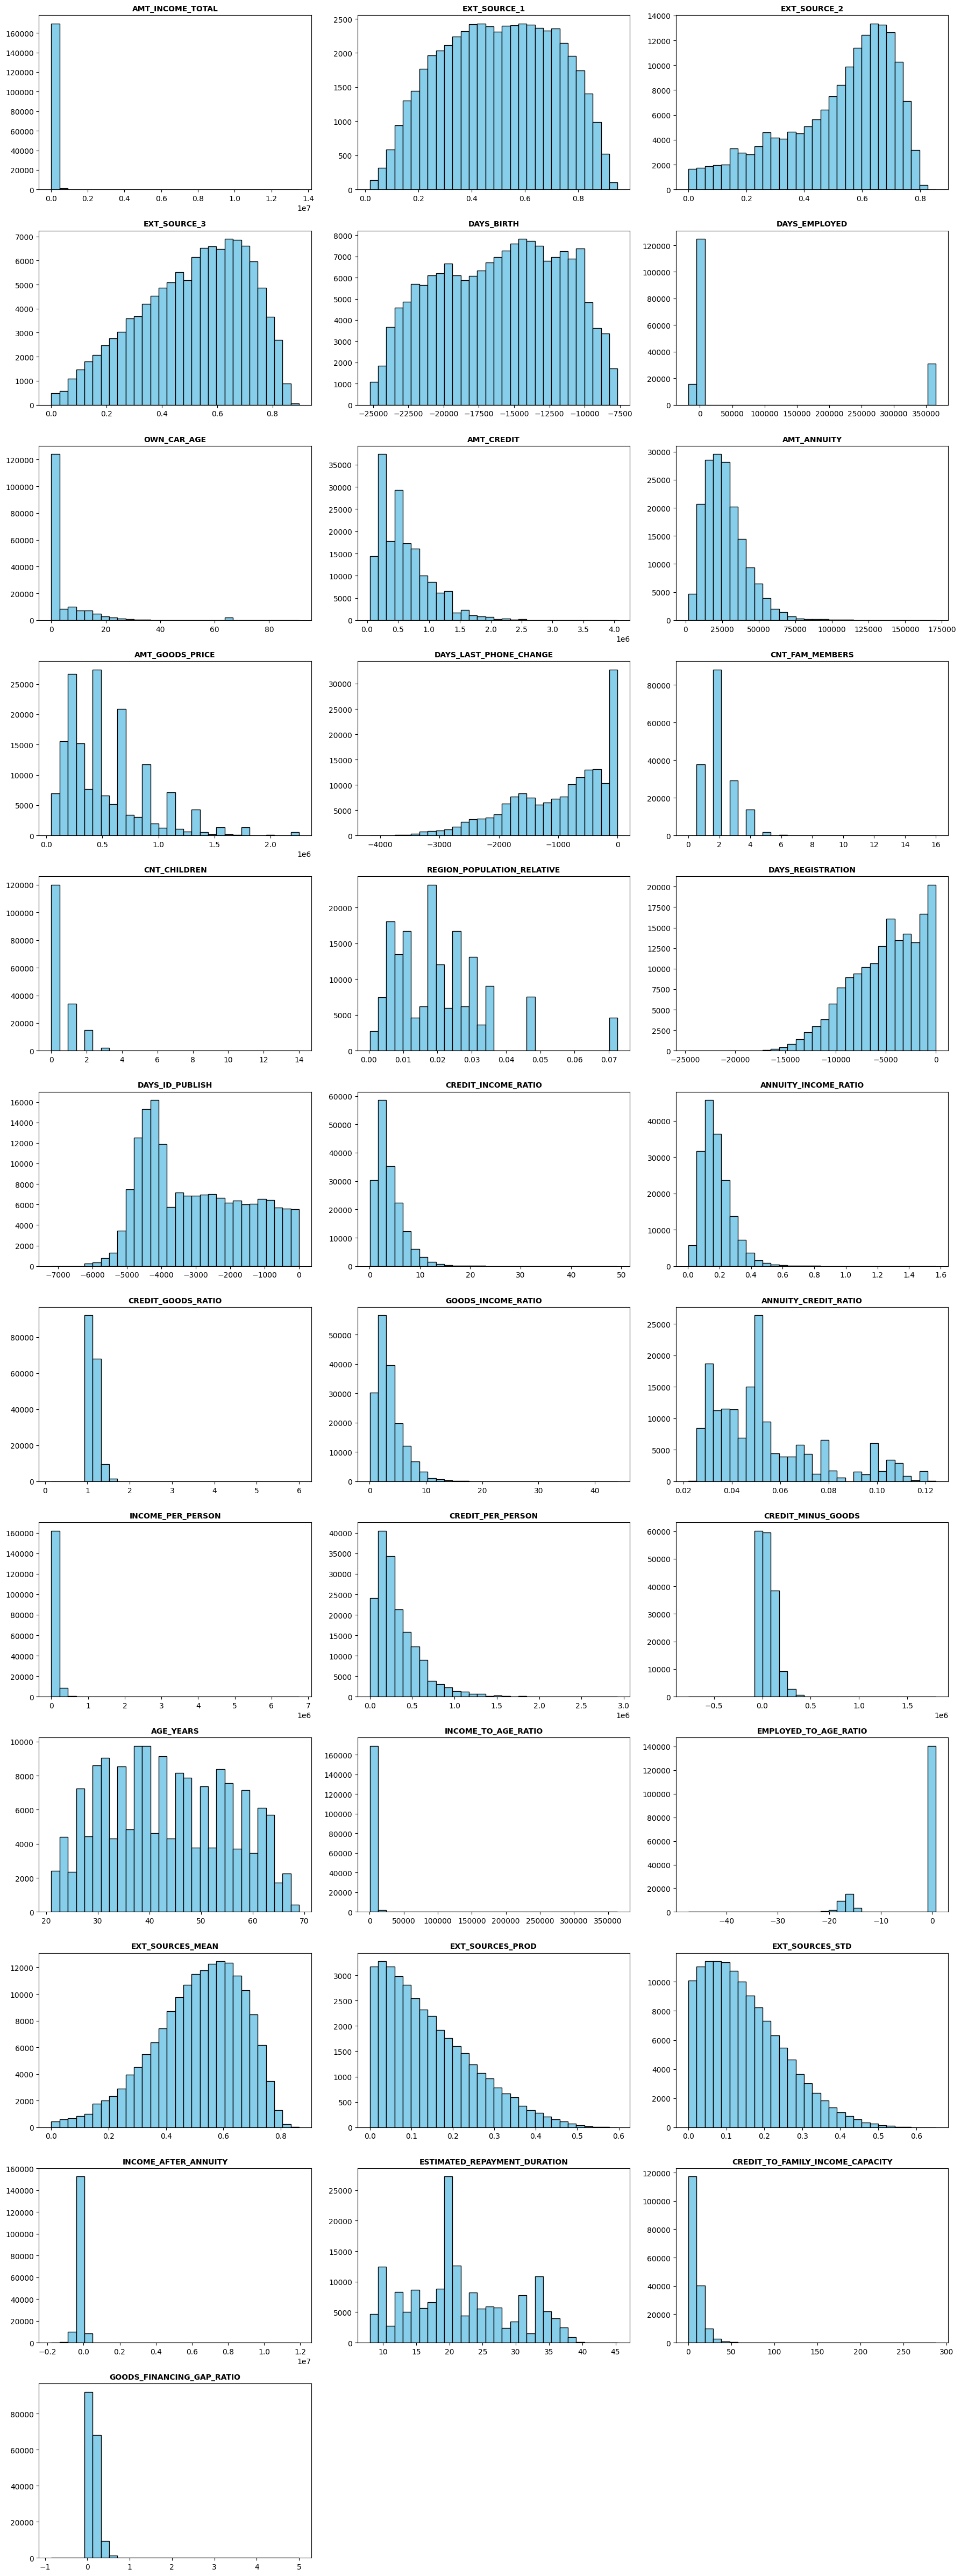

In [72]:
import matplotlib.pyplot as plt

# Select all numeric columns (both integers and floats)
numeric_cols = train.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

# Remove TARGET, IDs, or non-feature columns if they exist in the list
exclude_cols = ["TARGET", "SK_ID_CURR"]
numeric_cols = [col for col in numeric_cols if col not in exclude_cols]

# Set up the plotting grid (3 columns wide)
n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

# Plot histograms for each numeric/engineered column
for i, col in enumerate(numeric_cols):
    train[col].dropna().hist(
        ax=axes[i], bins=30, color="skyblue", edgecolor="black"
    )
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].grid(False)

# Hide any unused empty subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### ALL OBJECT COLUMN GRAPHS

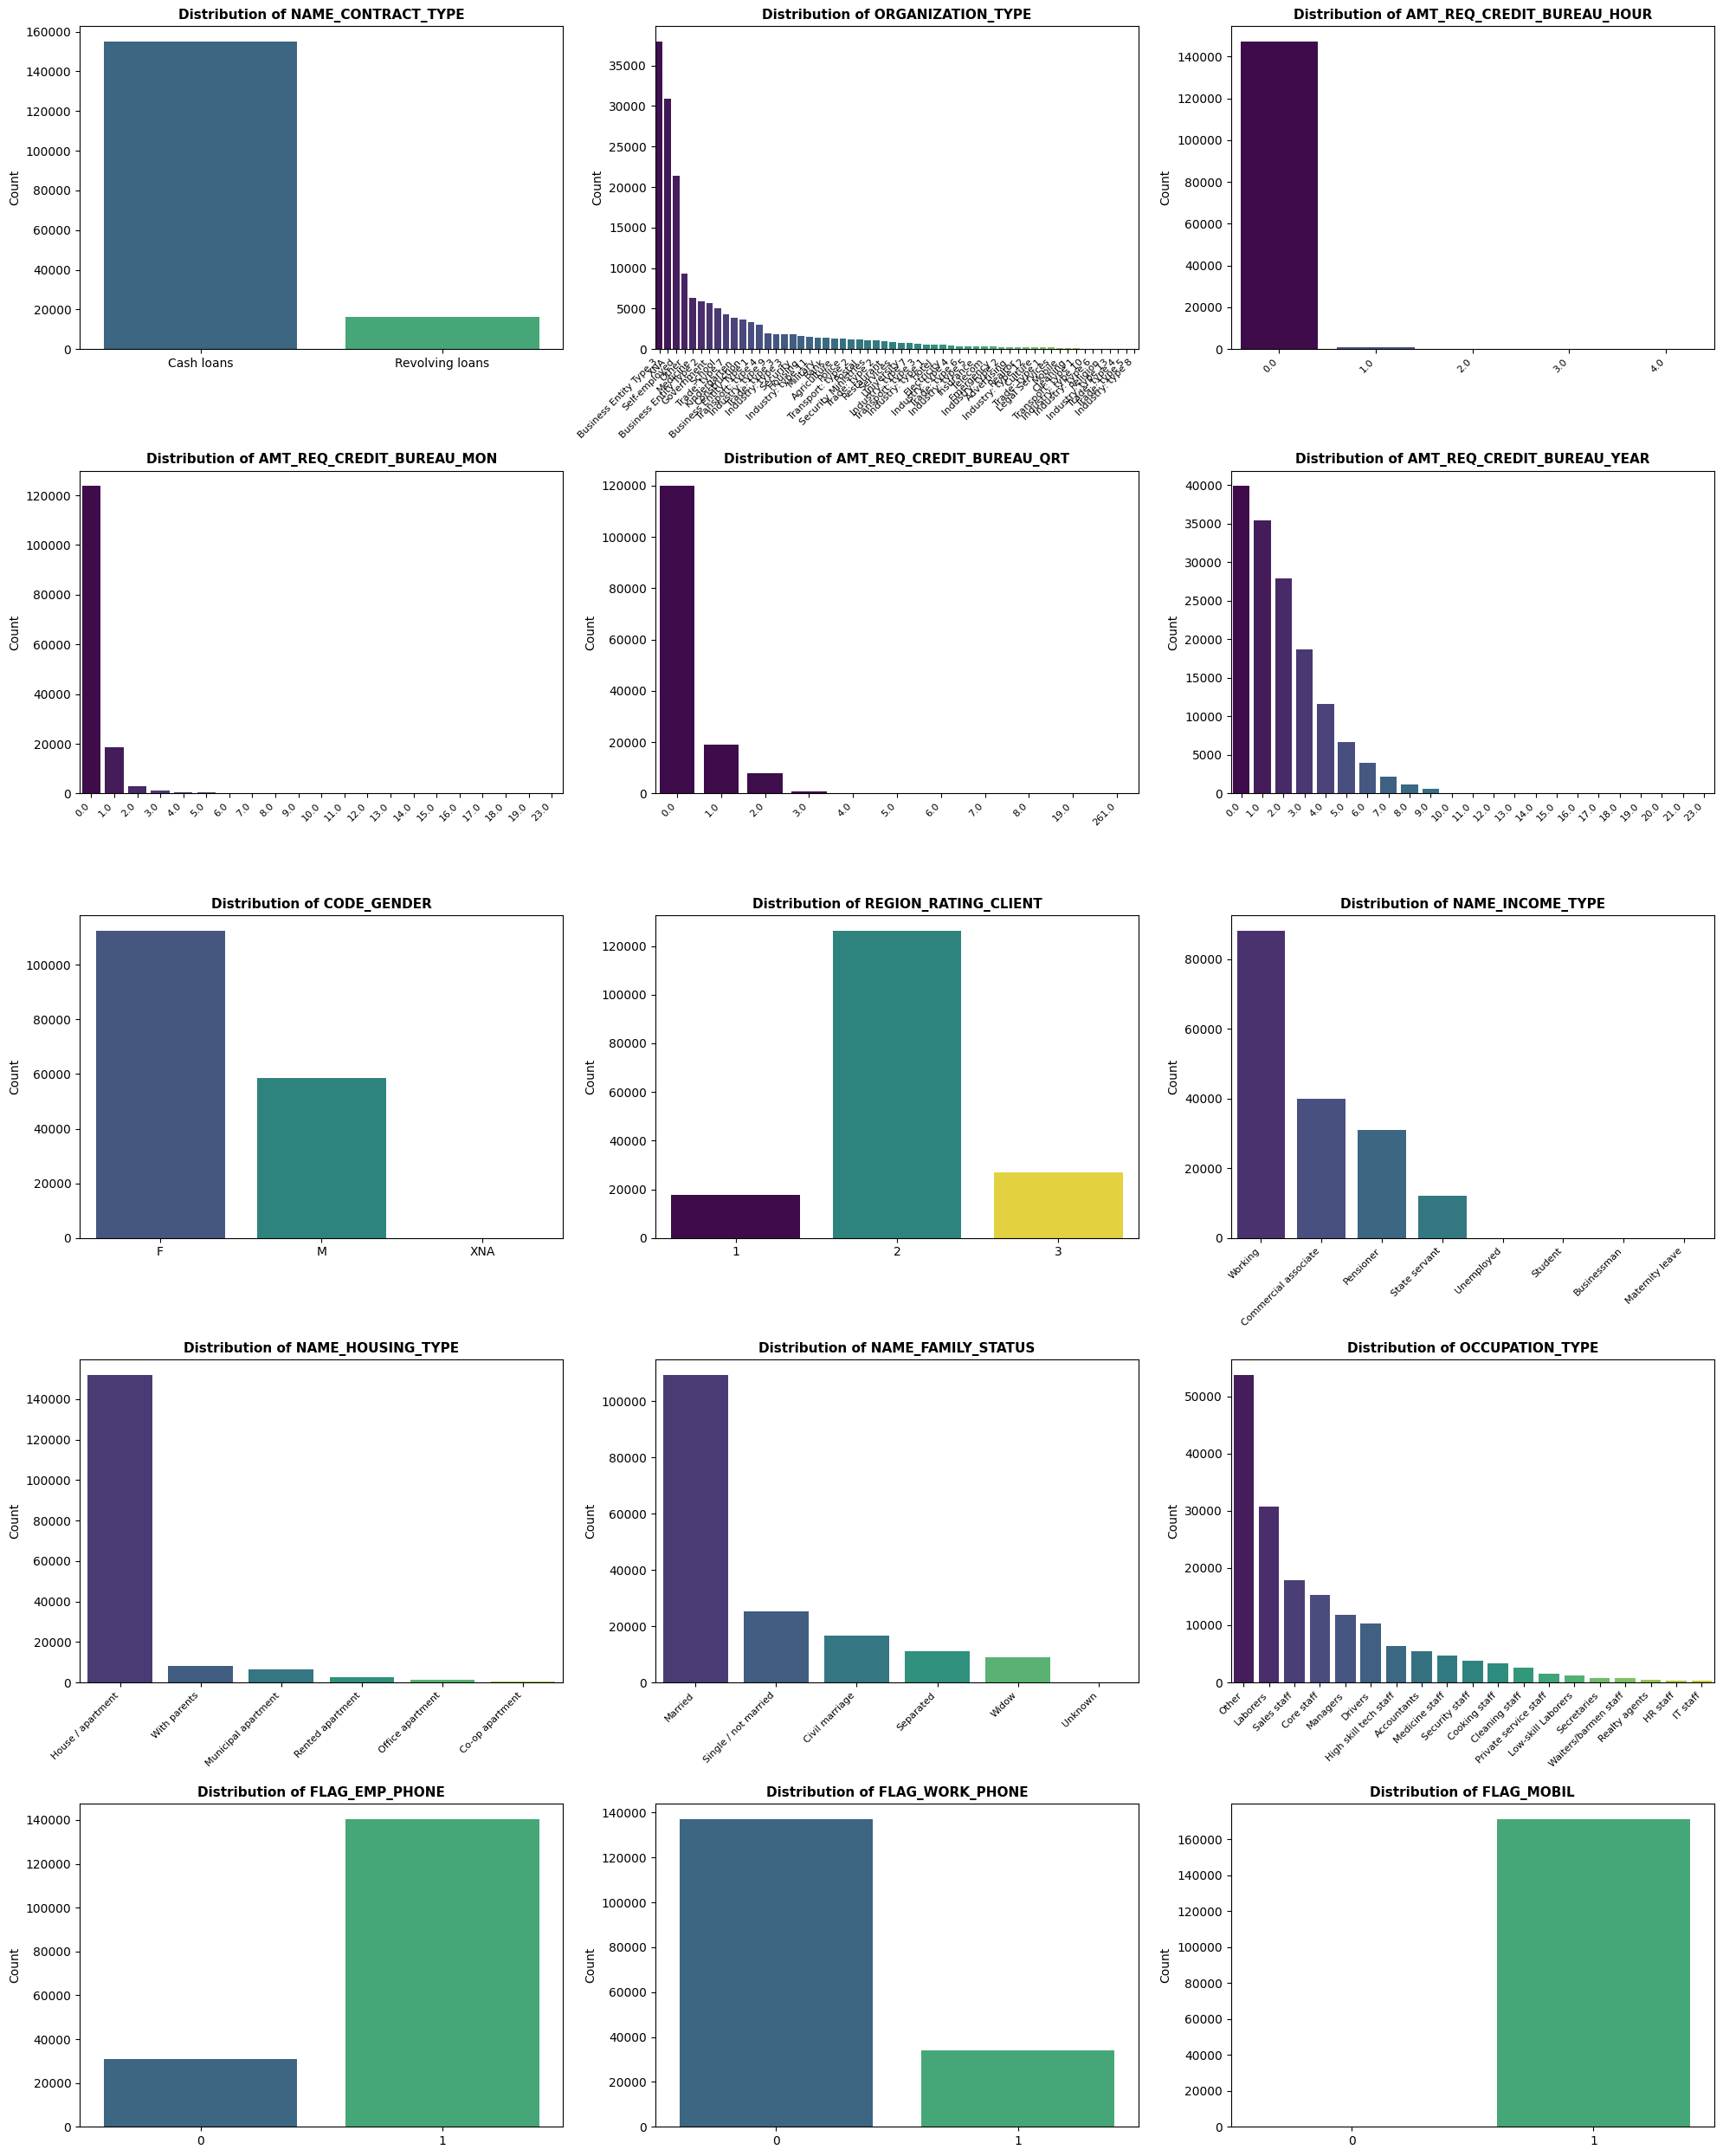

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get all object columns
obj_cols = train.select_dtypes(include=["object"]).columns.tolist()

# Set up the plotting grid (3 columns wide)
n_cols = 3
n_rows = (len(obj_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 5))
axes = axes.flatten()

for i, col in enumerate(obj_cols):
    # Count values, drop NaNs for plotting clarity, and sort descending
    value_counts = train[col].dropna().value_counts()

    # Plot using Seaborn barplot
    sns.barplot(
        x=value_counts.index,
        y=value_counts.values,
        ax=axes[i],
        palette="viridis",
        hue=value_counts.index,
        legend=False,
    )

    axes[i].set_title(f"Distribution of {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

    # Rotate x-axis labels if there are many categories (like Organization or Occupation)
    if len(value_counts) > 3:
        axes[i].tick_params(axis="x", rotation=45)
        # Align right for readability on rotated text
        for label in axes[i].get_xticklabels():
            label.set_ha("right")
            label.set_fontsize(8)
    else:
        axes[i].tick_params(axis="x", rotation=0)

# Hide any unused empty subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 4.Preprocessing and Feature Creation


In [74]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

def preprocess_home_credit_data(df: pd.DataFrame):
    """
    Applies custom domain-specific and statistical transformations to all continuous
    and discrete numerical features based on visual distribution profiles.
    """
    df = df.copy()

    # ---------------------------------------------------------
    # 1. ANOMALY CLEANING & FIXES
    # ---------------------------------------------------------
    # Handle the classic 365243 anomaly in DAYS_EMPLOYED
    if 'DAYS_EMPLOYED' in df.columns:
        df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
        df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

    # ---------------------------------------------------------
    # 2. MISSING VALUE INDICATORS & IMPUTATION
    # ---------------------------------------------------------
    ext_cols = ['EXT_SOURCES_MEAN', 'EXT_SOURCES_PROD', 'EXT_SOURCES_STD']
    for col in ext_cols:
        if col in df.columns:
            # Create explicit missing indicator column (crucial for GBDTs)
            df[f'{col}_IS_NA'] = df[col].isnull().astype(int)

    # Median Impute target EXT_SOURCES columns
    imputer = SimpleImputer(strategy='median')
    existing_ext = [c for c in ext_cols if c in df.columns]
    if existing_ext:
        df[existing_ext] = imputer.fit_transform(df[existing_ext])

    # ---------------------------------------------------------
    # 3. HEAVILY SKEWED FEATURES -> LOG1P TRANSFORM
    # ---------------------------------------------------------
    # Columns exhibiting heavy right-skew across histograms
    skewed_cols = [
        'AMT_INCOME_TOTAL', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO',
        'CREDIT_GOODS_RATIO', 'GOODS_INCOME_RATIO', 'INCOME_PER_PERSON',
        'CREDIT_PER_PERSON', 'INCOME_TO_AGE_RATIO', 'INCOME_AFTER_ANNUITY',
        'CREDIT_TO_FAMILY_INCOME_CAPACITY', 'AMT_CREDIT', 'AMT_ANNUITY',
        'AMT_GOODS_PRICE'
    ]

    for col in skewed_cols:
        if col in df.columns:
            # Shift minimum to 0 before log1p if negative values exist
            min_val = df[col].min()
            if min_val < 0:
                df[col] = np.log1p(df[col] - min_val)
            else:
                df[col] = np.log1p(df[col])

    # ---------------------------------------------------------
    # 4. OUTLIER CLIPPING (1st to 99th Percentile)
    # ---------------------------------------------------------
    # Prevents extreme spikes/leverage points from disrupting Logistic Regression
    unbounded_cols = [
        'AMT_INCOME_TOTAL', 'INCOME_PER_PERSON', 'CREDIT_PER_PERSON',
        'INCOME_TO_AGE_RATIO', 'CREDIT_TO_FAMILY_INCOME_CAPACITY',
        'GOODS_FINANCING_GAP_RATIO'
    ]

    for col in unbounded_cols:
        if col in df.columns:
            lower_bound = df[col].quantile(0.01)
            upper_bound = df[col].quantile(0.99)
            df[col] = np.clip(df[col], lower_bound, upper_bound)

In [75]:
import pandas as pd
import numpy as np

# 1. Define explicit list of categorical columns based on dataset info
cat_cols = [
    'NAME_CONTRACT_TYPE',
    'ORGANIZATION_TYPE',
    'CODE_GENDER',
    'NAME_INCOME_TYPE',
    'NAME_HOUSING_TYPE',
    'NAME_FAMILY_STATUS',
    'OCCUPATION_TYPE'
]

# Ensure missing values in categorical text columns are filled cleanly
for col in cat_cols:
    if col in train.columns:
        train[col] = train[col].fillna("Missing").astype(str)
        test[col] = test[col].fillna("Missing").astype(str)

# -------------------------------------------------------------------
# A. BINARY & ORDINAL ENCODING (For both Trees & Logistic Regression)
# -------------------------------------------------------------------
# Binary 0/1 mapping for NAME_CONTRACT_TYPE
if 'NAME_CONTRACT_TYPE' in train.columns:
    binary_map = {'Cash loans': 0, 'Revolving loans': 1}
    train['NAME_CONTRACT_TYPE'] = train['NAME_CONTRACT_TYPE'].map(binary_map).fillna(0).astype(int)
    test['NAME_CONTRACT_TYPE'] = test['NAME_CONTRACT_TYPE'].map(binary_map).fillna(0).astype(int)

# Binary 0/1 mapping for CODE_GENDER (handling minor XNA category safely)
if 'CODE_GENDER' in train.columns:
    gender_map = {'F': 0, 'M': 1, 'XNA': 0}
    train['CODE_GENDER'] = train['CODE_GENDER'].map(gender_map).fillna(0).astype(int)
    test['CODE_GENDER'] = test['CODE_GENDER'].map(gender_map).fillna(0).astype(int)

# -------------------------------------------------------------------
# B. HIGH-CARDINALITY FEATURE ENCODING (ORGANIZATION_TYPE & OCCUPATION_TYPE)
# -------------------------------------------------------------------
# Count/Frequency Encoding for high cardinality features (prevents sparse OHE matrices)
for col in ['ORGANIZATION_TYPE', 'OCCUPATION_TYPE']:
    if col in train.columns:
        freq_map = train[col].value_counts(normalize=True).to_dict()
        train[f'{col}_FREQ'] = train[col].map(freq_map).fillna(0)
        test[f'{col}_FREQ'] = test[col].map(freq_map).fillna(0)

# -------------------------------------------------------------------
# C. LABEL ENCODING PIPELINE (Optimal for XGBoost, CatBoost, RandomForest)
# -------------------------------------------------------------------
train_tree = train.copy()
test_tree = test.copy()

remaining_cats = ['ORGANIZATION_TYPE', 'NAME_INCOME_TYPE', 'NAME_HOUSING_TYPE', 'NAME_FAMILY_STATUS', 'OCCUPATION_TYPE']

for col in remaining_cats:
    if col in train_tree.columns:
        # Align categories deterministically between train and test
        categories = sorted(list(set(train_tree[col].unique()).union(set(test_tree[col].unique()))))
        cat_to_code = {cat: idx for idx, cat in enumerate(categories)}

        train_tree[col] = train_tree[col].map(cat_to_code).astype(int)
        test_tree[col] = test_tree[col].map(cat_to_code).astype(int)

# -------------------------------------------------------------------
# D. ONE-HOT ENCODING PIPELINE (Optimal for Logistic Regression)
# -------------------------------------------------------------------
# One-Hot Encode remaining nominal categorical columns to prevent linear distance bias
train_linear = pd.get_dummies(train, columns=remaining_cats, drop_first=True)
test_linear = pd.get_dummies(test, columns=remaining_cats, drop_first=True)

# Align columns between train_linear and test_linear (ensures identical columns)
train_linear, test_linear = train_linear.align(test_linear, join='left', axis=1, fill_value=0)

**NAME_FAMILY_STATUS**

In [76]:
# Safe Label Encoding for NAME_FAMILY_STATUS
for col in ["NAME_FAMILY_STATUS"]:
    combined = pd.concat([train[col], test[col]], axis=0).astype(str)
    categories = sorted(combined.unique())
    cat_to_code = {cat: idx for idx, cat in enumerate(categories)}

    train[col] = train[col].astype(str).map(cat_to_code).fillna(-1).astype(int)
    test[col] = test[col].astype(str).map(cat_to_code).fillna(-1).astype(int)

**OCCUPATION_TYPE**

In [77]:
# Fill missing text values with 'Unknown' and encode
col = "OCCUPATION_TYPE"
train[col] = train[col].fillna("Unknown").astype(str)
test[col] = test[col].fillna("Unknown").astype(str)

combined = pd.concat([train[col], test[col]], axis=0)
categories = sorted(combined.unique())
cat_to_code = {cat: idx for idx, cat in enumerate(categories)}

train[col] = train[col].map(cat_to_code).astype(int)
test[col] = test[col].map(cat_to_code).astype(int)

**FLAG_EMP_PHONE** & **FLAG_WORK_PHONE**

In [78]:
# Ensure binary flags have no missing values
flag_cols = ["FLAG_EMP_PHONE", "FLAG_WORK_PHONE"]
for col in flag_cols:
    train[col] = train[col].fillna(0).astype(int)
    test[col] = test[col].fillna(0).astype(int)

"NAME_EDUCATION_TYPE"

In [79]:
# Automatically find and encode any remaining object/text columns in train and test
categorical_cols = train.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    train[col] = train[col].astype('category').cat.codes
    test[col] = test[col].astype('category').cat.codes

# Also fill any remaining missing values with 0 so StandardScaler doesn't crash on NaNs
train.fillna(0, inplace=True)
test.fillna(0, inplace=True)

"NAME_INCOME_TYPE","NAME_HOUSING_TYPE","CODE_GENDER", "FLAG_OWN_REALTY"

In [80]:
# 1. Encode categorical text features (using label encoding / category codes)
cat_cols = ["NAME_INCOME_TYPE", "NAME_HOUSING_TYPE","CODE_GENDER", "FLAG_OWN_REALTY"]
for col in cat_cols:
    if col in train.columns:
        train[col] = train[col].astype('category').cat.codes
        test[col] = test[col].astype('category').cat.codes



"CNT_CHILDREN", "REGION_POPULATION_RELATIVE", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH"

In [81]:
# 2. Handle missing values for numerical features
num_cols = ["CNT_CHILDREN", "REGION_POPULATION_RELATIVE", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH","DAYS_LAST_PHONE_CHANGE", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT"]
for col in num_cols:
    if col in train.columns:
        train[col].fillna(train[col].median(), inplace=True)
        test[col].fillna(test[col].median(), inplace=True)

AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_QRT, and AMT_REQ_CREDIT_BUREAU_YEAR

In [82]:
# Fill missing bureau requests with 0 or -1
for col in ["AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR"]:
    train[col].fillna(0, inplace=True)
    test[col].fillna(0, inplace=True)

### EXT_SOURCE_2,2,3 column


In [83]:
# Fill missing values with -1 so trees can separate missing data cleanly
for col in ["EXT_SOURCE_1", "EXT_SOURCE_3"]:
    train[col].fillna(-1, inplace=True)
    test[col].fillna(-1, inplace=True)

In [84]:
# Complete missing values of EXT_SOURCE_2 with the average
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True) # Use average of train data to fill test data



### OWN_CAR_AGE column


In [85]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

In [86]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

train["OWN_CAR_AGE"].unique()

array([ 0.,  2.,  1., nan,  3.,  4.,  5.])

In [87]:
# Apply One Hot Encoding to OWN_CAR_AGE
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

# Add the one hot encoded columns to train/test
train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

# Remove original OWN_CAR_AGE
train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)



In [88]:
# Automatically find and encode any remaining object/text columns in train and test
categorical_cols = train.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    train[col] = train[col].astype('category').cat.codes
    test[col] = test[col].astype('category').cat.codes

# Also fill any remaining missing values with 0 so StandardScaler doesn't crash on NaNs
train.fillna(0, inplace=True)
test.fillna(0, inplace=True)

In [89]:
train.isnull().sum()

,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_1,0
EXT_SOURCE_2,0
EXT_SOURCE_3,0
DAYS_BIRTH,0
DAYS_EMPLOYED,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
DAYS_LAST_PHONE_CHANGE,0


In [90]:
train.head(5)

,AMT_INCOME_TOTAL,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH,DAYS_EMPLOYED,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_LAST_PHONE_CHANGE,...,FLAG_MOBIL,TARGET,ORGANIZATION_TYPE_FREQ,OCCUPATION_TYPE_FREQ,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,112500,0.000000,0.372591,0.000000,-9233,-878,755190,36328.5,675000,-292,...,1,0,0.029153,0.089199,True,False,False,False,False,False
1,225000,0.000000,0.449567,0.553165,-20148,365243,585000,16893.0,585000,-617,...,1,0,0.180477,0.313927,True,False,False,False,False,False
2,54000,0.000000,0.569503,0.000000,-18496,-523,334152,18256.5,270000,-542,...,1,0,0.006922,0.089199,True,False,False,False,False,False
3,67500,0.000000,0.105235,0.767523,-24177,365243,152820,8901.0,135000,0,...,1,0,0.180477,0.313927,True,False,False,False,False,False
4,157500,0.342344,0.202490,0.669057,-10685,-697,271066,21546.0,234000,-1243,...,1,1,0.221627,0.060472,True,False,False,False,False,False


## 5.Building the Machine Learning Model


### 5.1 Import Additional Libraries


In [91]:
# Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

### 5.2 Preparing the Data


In [92]:
# Split the data into explanatory and target variables
X = train.drop("TARGET", axis=1).values
y = train["TARGET"].values
X_test = test.values

In [93]:
# Standardization
sc = StandardScaler()
sc.fit(X)
X_std = sc.transform(X)
X_test_std = sc.transform(X_test)

### 5.3 Training the Model


In [94]:
# Split the original data into the training data and the validation data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y, test_size=0.3, stratify=y, random_state=0)

In [95]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=0)
lr.fit(X_train, y_train)

lr_train_pred = lr.predict_proba(X_train)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lr_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lr_valid_pred)}")

Train Score: 0.7339314900919313
Valid Score: 0.7334144966787037


In [96]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=0, max_depth=10)
rf.fit(X_train, y_train)

rf_train_pred = rf.predict_proba(X_train)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, rf_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, rf_valid_pred)}")

Train Score: 0.8498810904155396
Valid Score: 0.7377455685441768


In [97]:
#LightGBM
import lightgbm as lgb

# Initialize and train LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=914,        # More trees
    learning_rate=0.049648380482465684,      # Slower learning rate for better generalization
    num_leaves=61,           # Control tree complexity
    max_depth=4,             # Prevent deep overfitting
    subsample=0.8273148817183672,           # Row sampling per tree
    colsample_bytree=0.7694817067190632,    # Column sampling per split
    random_state=42,
    verbose=-1,
    reg_alpha=0.5574219968188143,
    reg_lambda=0.20714562153921381,
    n_jobs=-1
)
lgb_model.fit(X_train, y_train)

# Predict probabilities
lgb_train_pred = lgb_model.predict_proba(X_train)[:, 1]
lgb_valid_pred = lgb_model.predict_proba(X_valid)[:, 1]

print(f"Train Score: {roc_auc_score(y_train, lgb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lgb_valid_pred)}")

Train Score: 0.8502210106139567
Valid Score: 0.7557553000742414


In [98]:
!pip install optuna

In [99]:
# import optuna
# import lightgbm as lgb
# from sklearn.metrics import roc_auc_score

# def objective_lgb(trial):
#     params = {
#         'n_estimators': trial.suggest_int('n_estimators', 300, 1000),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.05, log=True),
#         'num_leaves': trial.suggest_int('num_leaves', 20, 64),
#         'max_depth': trial.suggest_int('max_depth', 4, 8),
#         'subsample': trial.suggest_float('subsample', 0.6, 1.0),
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
#         'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
#         'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
#         'random_state': 42,
#         'verbose': -1,
#         'n_jobs': -1
#     }

#     model = lgb.LGBMClassifier(**params)
#     model.fit(X_train, y_train)
#     preds = model.predict_proba(X_valid)[:, 1]
#     return roc_auc_score(y_valid, preds)

# # Run optimization study
# optuna.logging.set_verbosity(optuna.logging.WARNING)
# study_lgb = optuna.create_study(direction='maximize')
# study_lgb.optimize(objective_lgb, n_trials=20)

# print("Best LightGBM Validation AUC:", study_lgb.best_value)
# print("Best LightGBM Parameters:", study_lgb.best_params)

In [100]:
!pip install catboost

In [101]:
# CatBoost Model
from catboost import CatBoostClassifier

cb_model = CatBoostClassifier(
    iterations=1140,
    learning_rate=0.0633531402177257,
    depth=5,
    eval_metric='AUC',
    random_seed=42,
    verbose=0,
    l2_leaf_reg=8.210712600359598
)
cb_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=50)

# Predict probabilities
cb_train_pred = cb_model.predict_proba(X_train)[:, 1]
cb_valid_pred = cb_model.predict_proba(X_valid)[:, 1]

print(f"Train Score: {roc_auc_score(y_train, cb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, cb_valid_pred)}")

Train Score: 0.7970810664348154
Valid Score: 0.755922995765233


In [102]:
# from catboost import CatBoostClassifier

# def objective_cb(trial):
#     params = {
#         'iterations': trial.suggest_int('iterations', 500, 1200),
#         'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.08, log=True),
#         'depth': trial.suggest_int('depth', 4, 8),
#         'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
#         'random_seed': 42,
#         'eval_metric': 'AUC',
#         'verbose': 0
#     }

#     model = CatBoostClassifier(**params)
#     model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=50)
#     preds = model.predict_proba(X_valid)[:, 1]
#     return roc_auc_score(y_valid, preds)

# # Run optimization study
# study_cb = optuna.create_study(direction='maximize')
# study_cb.optimize(objective_cb, n_trials=20)

# print("Best CatBoost Validation AUC:", study_cb.best_value)
# print("Best CatBoost Parameters:", study_cb.best_params)

### 5.4 (Optional) Ensemble Learning


In [103]:
train_pred = (lr_train_pred + rf_train_pred) / 2
valid_pred = (lr_valid_pred + rf_valid_pred) / 2

print(f"Train Score: {roc_auc_score(y_train, train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, valid_pred)}")

Train Score: 0.8042081986587214
Valid Score: 0.7396352267513732


In [104]:
# Blend predictions
ensemble_valid_pred = (0.8 * lgb_valid_pred) + (0.2 * rf_valid_pred)

# Check the new ensemble validation score
print(f"Ensemble Valid Score: {roc_auc_score(y_valid, ensemble_valid_pred)}")

Ensemble Valid Score: 0.7563224371235665


In [105]:
# Blend predictions from LightGBM and CatBoost
ensemble_valid_pred = (0.6 * lgb_valid_pred) + (0.4 * cb_valid_pred)

# Check the new ensemble validation score
print(f"Ensemble Valid Score: {roc_auc_score(y_valid, ensemble_valid_pred)}")

Ensemble Valid Score: 0.7580240372848717


## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found in Sections 5.3 and 5.4 that the best model was random forest model. Therefore, we will use this model to make the final prediction.

If you made any changes and found a better model, you will need to change the code below accordingly.

```python
# If logistic regression model was better
pred = lr.predict_proba(X_test_std)[:, 1]
```

In [106]:
# Generate test probabilities for both LightGBM and CatBoost models
lgb_test_pred = lgb_model.predict_proba(X_test_std)[:, 1]
cb_test_pred = cb_model.predict_proba(X_test_std)[:, 1]

# Blend the test predictions using your optimized weights (60% LightGBM + 40% CatBoost)
pred = (0.6 * lgb_test_pred) + (0.4 * cb_test_pred)

### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [107]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.027780
1,171203,0.220597
2,171204,0.133705
3,171205,0.107397
4,171206,0.214201
...,...,...
61495,232697,0.140711
61496,232698,0.032773
61497,232699,0.056508
61498,232700,0.228027


In [108]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`tutorial.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [109]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")

Successfully created: /content/drive/MyDrive/Competition/tutorial.zip
